# 03.4 · Logistic regression: the sigmoid and probabilities

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/04-logistic-regression/lesson.ipynb)

Read the [README](README.md) and compute the sigmoid values and the two predictions on paper first. Here you write `sigmoid()`, reproduce `predict_proba` by hand from the coefficients, compute log loss, draw the boundary, and build the churn ranking on real data.

## 1. The sigmoid

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


σ(-2) = 0.119
σ( 0) = 0.500
σ( 2) = 0.881


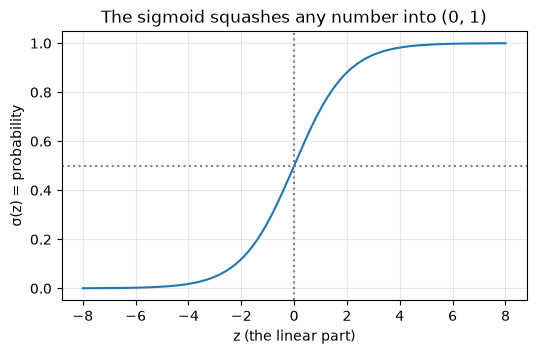

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-2, 0, 2]:
    print(f"σ({z:>2}) = {sigmoid(z):.3f}")

zs = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3.5)); plt.plot(zs, sigmoid(zs))
plt.axhline(0.5, color="gray", linestyle=":"); plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("z (the linear part)"); plt.ylabel("σ(z) = probability"); plt.title("The sigmoid squashes any number into (0, 1)")
plt.grid(alpha=.3); plt.show()

## 2. Fit logistic regression on the 20 customers

In [3]:
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression().fit(X20, y20)
m_visits, m_days = logit.coef_[0]
c = logit.intercept_[0]
print(f"z = {c:.2f} + ({m_visits:.2f}) × visits + ({m_days:.3f}) × days")
print(f"accuracy on the 20 customers: {logit.score(X20, y20):.0%}")

z = 3.13 + (-0.60) × visits + (0.052) × days
accuracy on the 20 customers: 90%


## 3. Reproduce `predict_proba` by hand

Compute $z$ for every customer from the coefficients, push it through the sigmoid, and compare with scikit-learn's column.

In [4]:
z = c + m_visits * cust20["visits_last_month"] + m_days * cust20["days_since_last"]
p_hand = sigmoid(z)
p_sklearn = logit.predict_proba(X20)[:, 1]

check = cust20[["customer_id", "visits_last_month", "days_since_last", "churned"]].copy()
check["z"] = z.round(2); check["p_hand"] = p_hand.round(3); check["p_sklearn"] = p_sklearn.round(3)
check.loc[check["customer_id"].isin(["C001", "C005", "C012"])]

,customer_id,visits_last_month,days_since_last,churned,z,p_hand,p_sklearn
0,C001,2,55,1,4.80,0.992,0.992
4,C005,7,25,1,0.22,0.555,0.555
11,C012,14,12,0,-4.67,0.009,0.009


C001 → 0.99, C012 → 0.01, C005 → 0.56, as on paper. `predict` is just `p > 0.5`:

In [5]:
print("by hand :", (p_hand > 0.5).astype(int).values)
print("sklearn :", logit.predict(X20))

by hand : [1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 0 1 0 1]
sklearn : [1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 0 1 0 1]


## 4. Log loss: what training minimises

In [6]:
def log_loss_one(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

print(f"churner predicted 0.99 → loss {log_loss_one(1, 0.99):.3f}")
print(f"churner predicted 0.10 → loss {log_loss_one(1, 0.10):.3f}   (confident and wrong)")
print(f"stayer  predicted 0.10 → loss {log_loss_one(0, 0.10):.3f}")

from sklearn.metrics import log_loss
print(f"\nmean log loss of the fitted model: {log_loss(y20, p_sklearn):.3f}")
print(f"mean log loss of 'always 0.5':      {log_loss(y20, np.full(20, 0.5)):.3f}")

churner predicted 0.99 → loss 0.010
churner predicted 0.10 → loss 2.303   (confident and wrong)
stayer  predicted 0.10 → loss 0.105

mean log loss of the fitted model: 0.333
mean log loss of 'always 0.5':      0.693


## 5. Odds and what the coefficients mean

In [7]:
print(f"visits: coefficient {m_visits:.2f} → odds multiplier e^{m_visits:.2f} = {np.exp(m_visits):.2f} per extra visit")
print(f"days:   coefficient {m_days:.3f} → odds multiplier e^{m_days:.3f} = {np.exp(m_days):.3f} per extra day")
print(f"        ten extra days → {np.exp(10 * m_days):.2f}× the odds of churn")

visits: coefficient -0.60 → odds multiplier e^-0.60 = 0.55 per extra visit
days:   coefficient 0.052 → odds multiplier e^0.052 = 1.054 per extra day
        ten extra days → 1.68× the odds of churn


## 6. The boundary is a straight line

Logistic regression predicts churn where $z > 0$. That is a line in the (visits, days) plane; the probability shades smoothly across it.

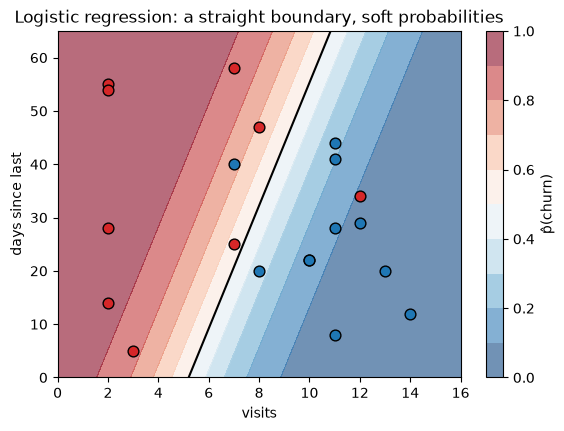

In [8]:
vv, dd = np.meshgrid(np.linspace(0, 16, 200), np.linspace(0, 65, 200))
grid = pd.DataFrame({"visits_last_month": vv.ravel(), "days_since_last": dd.ravel()})
pp = logit.predict_proba(grid)[:, 1].reshape(vv.shape)

plt.figure(figsize=(6.5, 4.5))
cs = plt.contourf(vv, dd, pp, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=.6)
plt.colorbar(cs, label="p̂(churn)")
plt.contour(vv, dd, pp, levels=[0.5], colors="k")
for label, colour in [(0, "tab:blue"), (1, "tab:red")]:
    sub = cust20[cust20["churned"] == label]
    plt.scatter(sub["visits_last_month"], sub["days_since_last"], c=colour, s=60, edgecolor="k")
plt.xlabel("visits"); plt.ylabel("days since last"); plt.title("Logistic regression: a straight boundary, soft probabilities")
plt.show()

## 7. The real data: a ranked voucher list

In [9]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logit_real = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"baseline {baseline:.1%}   logistic regression {logit_real.score(X_test, y_test):.1%}")

coefs = pd.Series(logit_real[-1].coef_[0], index=features).round(2)
print("\nscaled coefficients (negative = lowers churn):")
print(coefs.sort_values())

baseline 56.4%   logistic regression 67.5%

scaled coefficients (negative = lowers churn):
orders            -0.99
products          -0.45
tenure_days       -0.17
spend              0.06
days_since_last    0.44
dtype: float64


In [11]:
# the ranking retention asked for: top 500 test customers by churn probability
scored = X_test.copy()
scored["p_churn"] = logit_real.predict_proba(X_test)[:, 1]
scored["churned"] = y_test
top = scored.sort_values("p_churn", ascending=False).head(500)
print(f"top 500 by p̂: {top['churned'].mean():.1%} actually churned")
print(f"500 at random: {scored.sample(500, random_state=0)['churned'].mean():.1%} actually churned")
top.head()

top 500 by p̂: 57.4% actually churned
500 at random: 43.8% actually churned


,orders,spend,products,tenure_days,days_since_last,p_churn,churned
Customer ID,,,,,,,
16754.0,1,2002.4,2,272,272,0.754843,1
13747.0,1,79.6,1,273,273,0.752859,1
15070.0,1,106.2,1,272,272,0.752275,1
12855.0,1,38.1,3,272,272,0.749400,1
14821.0,1,48.8,2,266,266,0.746918,1


About 57% of the model's top 500 really churned, against 44% for 500 picked at random. That lift is what the voucher budget buys, and it is understated here: the test set has only 830 customers, so "top 500" is already 60% of everyone. Look at the top rows: one order, nine months ago, probabilities around 0.75. Fit on everything and score all 3,300 before handing the real list to retention (exercise 4).

## Quiz answers

1. It squashes any real number into (0, 1) so the output can be read as a probability; a bare linear model has no upper or lower limit.
2. $\sigma(0) = 0.5$. $z = 0$ is the decision boundary: exactly undecided.
3. Large: $-\ln 0.01 = 4.6$. Log loss punishes confident mistakes hardest.
4. Customers who placed more orders before the cut-off are much less likely to churn, holding the other features fixed.
5. Churners forming a ring (or any island) inside the feature space: no straight line separates an island, but a tree's boxes can.

**Next:** [03.5 Naive Bayes](../05-naive-bayes/) (optional) or [03.6 The confusion matrix](../06-confusion-matrix-metrics/)